# Task 1 – Statistical POS Tagger and PCFG Parser from the Penn Treebank

**Goal:** build a statistical model from the labelled Penn Treebank (PTB) *training* data that:

1. assigns POS tags from the tag-transition and word-emission probabilities (a **bigram Hidden Markov Model**, decoded with Viterbi), and
2. scores grammatical structure with a **Probabilistic Context-Free Grammar (PCFG)** induced from the treebank parse trees (parsed with a probabilistic CKY algorithm).

**About the data source.** The Kaggle *Penn Treebank Dataset* (`ptb.train.txt`, `ptb.valid.txt`, `ptb.test.txt`) is the Mikolov language-modelling version of the PTB. It is lower-cased, has numbers replaced by `N` and rare words by `<unk>`, and contains **no POS tags and no parse trees**, so it cannot be used to estimate tag or grammar probabilities. As the brief says (*"Use NLTK Penn TreeBank Dataset for downloading – Labeled"*), the labelled training data is taken from NLTK's `treebank` corpus: the tagged and parsed Wall Street Journal (WSJ) section of the PTB (files `wsj_0001`–`wsj_0199`, 3,914 sentences). Only this labelled training material is used; no validation or test split of the Kaggle data is touched. Section 7 optionally loads `ptb.train.txt`, if it is present, as a vocabulary reference.

**Outputs (the "PCFG parser data", written to `model/`):**

| File | Contents |
|---|---|
| `tag_counts.csv` | frequency and relative frequency of each tag |
| `transition_matrix.csv` | P(tagᵢ \| tagᵢ₋₁), (45 tags + start/end states) |
| `transition_counts.csv` | raw tag-bigram counts |
| `emission_probs.csv` | P(word \| tag) for every (word, tag) pair seen in training |
| `unknown_word_model.csv` | P(signature \| tag) for unseen words |
| `pcfg_grammar_lexicalised.txt` | full PCFG induced from the treebank (all rules, including word rules) |
| `pcfg_rules.csv` | the same grammar as a table (LHS, RHS, count, probability) |
| `pcfg_parser_grammar_cnf.txt` | binarised (CNF) tag-level grammar used by the CKY parser |
| `pos_pcfg_model.pkl` | everything above in one file, loaded by the Task 3 notebook |

In [1]:
import os, re, math, pickle, random, collections, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.tree import Tree
from nltk.grammar import induce_pcfg, Nonterminal

# Some sandboxed/proxied networks block NLTK's downloader. The next line only matters there.
os.environ.setdefault("NLTK_ALLOW_PROXIED_URLOPEN", "1")
nltk.download("treebank", quiet=True)
from nltk.corpus import treebank

os.makedirs("model", exist_ok=True)
pd.set_option("display.max_columns", 60)
random.seed(42); np.random.seed(42)
print("NLTK", nltk.__version__)

NLTK 3.10.3


## 1. Load and inspect the labelled training corpus

In [2]:
fileids = treebank.fileids()
tagged_raw = [s for f in fileids for s in treebank.tagged_sents(f)]
parsed_raw = [t for f in fileids for t in treebank.parsed_sents(f)]

# Remove empty elements (traces, null complementisers), which are tagged -NONE-.
# They are not pronounced words, so they must not affect tag or word statistics.
tagged_sents = [[(w, t) for (w, t) in s if t != "-NONE-"] for s in tagged_raw]
tagged_sents = [s for s in tagged_sents if s]

n_tok = sum(len(s) for s in tagged_sents)
print(f"Files: {len(fileids)}  Sentences: {len(tagged_sents)}  Tokens (no traces): {n_tok}")
print("Example:", tagged_sents[0])

Files: 199  Sentences: 3914  Tokens (no traces): 94084
Example: [('Pierre', 'NNP'), ('Vinken', 'NNP'), (',', ','), ('61', 'CD'), ('years', 'NNS'), ('old', 'JJ'), (',', ','), ('will', 'MD'), ('join', 'VB'), ('the', 'DT'), ('board', 'NN'), ('as', 'IN'), ('a', 'DT'), ('nonexecutive', 'JJ'), ('director', 'NN'), ('Nov.', 'NNP'), ('29', 'CD'), ('.', '.')]


In [3]:
# Penn Treebank tag set (45 tags incl. punctuation; NLTK spells brackets -LRB-/-RRB-)
PTB_TAGS = {
 "CC":"Coordinating conjunction","CD":"Cardinal number","DT":"Determiner","EX":"Existential there",
 "FW":"Foreign word","IN":"Preposition / subordinating conjunction","JJ":"Adjective","JJR":"Adjective, comparative",
 "JJS":"Adjective, superlative","LS":"List item marker","MD":"Modal","NN":"Noun, singular or mass",
 "NNS":"Noun, plural","NNP":"Proper noun, singular","NNPS":"Proper noun, plural","PDT":"Predeterminer",
 "POS":"Possessive ending","PRP":"Personal pronoun","PRP$":"Possessive pronoun","RB":"Adverb",
 "RBR":"Adverb, comparative","RBS":"Adverb, superlative","RP":"Particle","SYM":"Symbol","TO":"to",
 "UH":"Interjection","VB":"Verb, base form","VBD":"Verb, past tense","VBG":"Verb, gerund / present participle",
 "VBN":"Verb, past participle","VBP":"Verb, non-3rd person singular present","VBZ":"Verb, 3rd person singular present",
 "WDT":"Wh-determiner","WP":"Wh-pronoun","WP$":"Possessive wh-pronoun","WRB":"Wh-adverb",
 "#":"Pound sign","$":"Dollar sign",".":"Sentence-final punctuation",",":"Comma",":":"Colon, semi-colon, dash",
 "``":"Opening quotation mark","''":"Closing quotation mark","-LRB-":"Left bracket","-RRB-":"Right bracket"}

tag_freq = collections.Counter(t for s in tagged_sents for _, t in s)
tag_df = (pd.DataFrame({"tag": list(tag_freq), "count": list(tag_freq.values())})
          .assign(description=lambda d: d.tag.map(PTB_TAGS).fillna("(non-standard)"),
                  rel_freq=lambda d: d["count"] / d["count"].sum())
          .sort_values("count", ascending=False).reset_index(drop=True))
tag_df.to_csv("model/tag_counts.csv", index=False)
print("Tags observed:", len(tag_df), "| not in the standard list:", sorted(set(tag_freq) - set(PTB_TAGS)))
tag_df.head(46)

Tags observed: 45 | not in the standard list: []


,tag,count,description,rel_freq
0,NN,13166,"Noun, singular or mass",0.139939
1,IN,9857,Preposition / subordinating conjunction,0.104768
2,NNP,9410,"Proper noun, singular",0.100017
3,DT,8165,Determiner,0.086784
4,NNS,6047,"Noun, plural",0.064272
5,JJ,5834,Adjective,0.062008
6,",",4886,Comma,0.051932
7,.,3874,Sentence-final punctuation,0.041176
8,CD,3546,Cardinal number,0.037690
9,VBD,3043,"Verb, past tense",0.032343


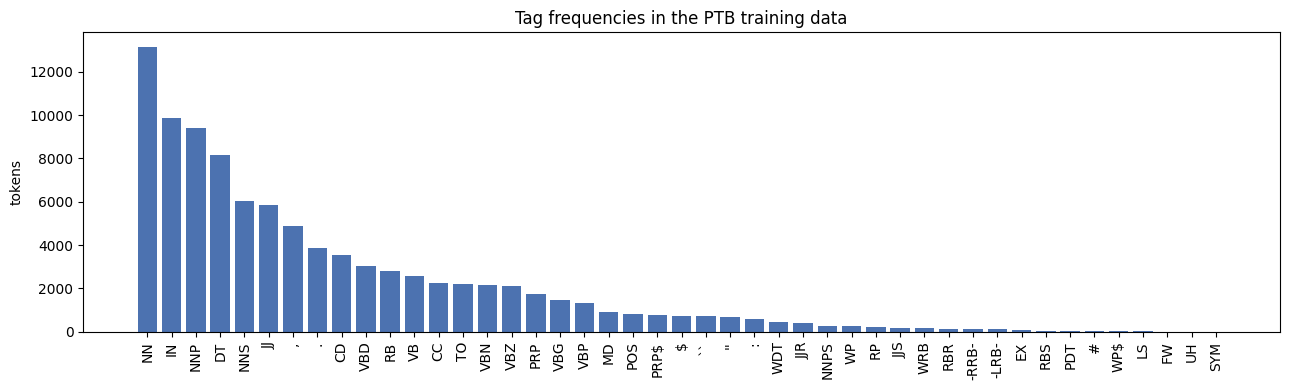

In [4]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.bar(tag_df.tag, tag_df["count"], color="#4C72B0")
ax.set_title("Tag frequencies in the PTB training data"); ax.set_ylabel("tokens")
plt.xticks(rotation=90); plt.tight_layout(); plt.savefig("model/tag_frequencies.png", dpi=120); plt.show()

## 2. The statistical POS model (bigram HMM)

For a sentence w₁…wₙ with tags t₁…tₙ the model scores

$$P(w_{1..n}, t_{1..n}) = \prod_{i=1}^{n+1} P(t_i \mid t_{i-1}) \; \prod_{i=1}^{n} P(w_i \mid t_i), \qquad t_0=\langle s\rangle,\; t_{n+1}=\langle /s\rangle$$

**Transition probabilities** are estimated from tag-bigram counts with add-k (Lidstone) smoothing, *k* = 0.1, so that no tag sequence gets zero probability:

$$P(t_i\mid t_{i-1}) = \frac{C(t_{i-1},t_i)+k}{C(t_{i-1})+k\,|T|}$$

**Emission probabilities** P(w | t) for known words use add-ε smoothing over the vocabulary V (ε = 0.001). A tag never seen with a word is possible but heavily penalised:

$$P(w\mid t) = \frac{C(w,t)+\varepsilon}{C(t)+\varepsilon |V|}$$

**Unseen words** are handled with word *signatures*: a word's shape (capitalised, digits, hyphen) plus its suffix (e.g. `UNK-CAP`, `UNK-ing`). The model is estimated from words seen only once in training (hapax legomena), which behave most like new words:

$$P(w_{unk}\mid t) = \underbrace{\frac{H(t)+0.01}{C(t)+1}}_{P(\text{unseen}\mid t)} \cdot \underbrace{\frac{H(sig(w),t)+P(sig(w))}{H(t)+1}}_{P(sig\mid \text{unseen},t)}$$

Here H(t) is the number of hapax tokens with tag t. Open classes (NN, NNP, JJ, VBN…) therefore receive unseen words, while closed classes (DT, IN, CC, UH, FW…) almost never do.

Word lookup tries the exact form first and then the lower-cased form, so sentence-initial capitals are not treated as unknown.

In [5]:
SUFFIXES = ["tion","sion","ment","ness","able","ible","ing","ity","ous","ful","ive","est","ers","ies","ed","ly","al","er","ic","s"]

def word_signature(w):
    sig = "UNK"
    if any(c.isdigit() for c in w): sig += "-NUM"
    if w[:1].isupper(): sig += "-CAP"
    if "-" in w: sig += "-HYPH"
    lw = w.lower()
    for suf in SUFFIXES:
        if lw.endswith(suf) and len(lw) > len(suf) + 1:
            sig += "-" + suf; break
    return sig

def train_hmm(sents, k=0.1, unk_alpha=0.1):
    tag_c, word_c = collections.Counter(), collections.Counter()
    wt_c = collections.defaultdict(collections.Counter)      # word -> tag -> count
    bigram_c = collections.defaultdict(collections.Counter)  # prev -> tag -> count
    for s in sents:
        prev = "<s>"
        for w, t in s:
            tag_c[t] += 1; word_c[w] += 1; wt_c[w][t] += 1
            bigram_c[prev][t] += 1; prev = t
        bigram_c[prev]["</s>"] += 1
    tags = sorted(tag_c)
    # transitions
    from_states, to_states = ["<s>"] + tags, tags + ["</s>"]
    trans = {}
    for p in from_states:
        tot = sum(bigram_c[p].values())
        trans[p] = {t: (bigram_c[p][t] + k) / (tot + k * len(to_states)) for t in to_states}
    # unknown-word model from hapax words
    hap = collections.defaultdict(collections.Counter)
    for w, c in word_c.items():
        if c == 1:
            for t, n in wt_c[w].items(): hap[t][word_signature(w)] += n
    sigs = sorted({s for t in hap for s in hap[t]} | {"UNK"})
    # P(unseen word with signature s | t) = P(unseen | t) * P(s | unseen, t)
    #   P(unseen | t): share of tag t's tokens that are hapax words -> close to 0 for closed classes (DT, IN, UH...)
    #   P(s | unseen, t): hapax signature counts, smoothed towards the overall signature distribution
    hap_tot = collections.Counter({s: sum(hap[t][s] for t in hap) for s in sigs})
    H = sum(hap_tot.values())
    p_sig = {s: (hap_tot[s] + unk_alpha) / (H + unk_alpha * len(sigs)) for s in sigs}
    unk = {}
    for t in tags:
        ht = sum(hap[t].values())
        p_unseen = (ht + 0.01) / (tag_c[t] + 1)
        unk[t] = {s: p_unseen * (hap[t][s] + p_sig[s]) / (ht + 1) for s in sigs}
    return dict(tags=tags, tag_counts=dict(tag_c), word_counts=dict(word_c),
                wt_counts={w: dict(c) for w, c in wt_c.items()},
                bigram_counts={p: dict(c) for p, c in bigram_c.items()},
                trans=trans, unk=unk, signatures=sigs, k=k)

def lookup(hmm, w):
    if w in hmm["wt_counts"]: return w
    if w.lower() in hmm["wt_counts"]: return w.lower()
    return None

def emit_prob(hmm, w, t):
    s = word_signature(w)
    pu = hmm["unk"][t].get(s, hmm["unk"][t]["UNK"])
    key = lookup(hmm, w)
    if key is None:
        return pu
    # known word: add-epsilon smoothing over the vocabulary, so a tag never seen with this word
    # is possible but strongly penalised (rare tags such as FW/UH no longer attract common words)
    eps = 0.001
    return (hmm["wt_counts"][key].get(t, 0) + eps) / (hmm["tag_counts"][t] + eps * len(hmm["word_counts"]))

def viterbi(hmm, words):
    tags, T = hmm["tags"], hmm["trans"]
    lt = {p: {t: math.log(v) for t, v in T[p].items()} for p in T}
    V = [{t: lt["<s>"][t] + math.log(emit_prob(hmm, words[0], t)) for t in tags}]
    back = [{}]
    for i in range(1, len(words)):
        V.append({}); back.append({})
        em = {t: math.log(emit_prob(hmm, words[i], t)) for t in tags}
        for t in tags:
            best_p, best = max(((V[i-1][p] + lt[p][t], p) for p in tags))
            V[i][t] = best_p + em[t]; back[i][t] = best
    best_score, last = max((V[-1][t] + lt[t]["</s>"], t) for t in tags)
    path = [last]
    for i in range(len(words) - 1, 0, -1):
        path.append(back[i][path[-1]])
    return path[::-1], best_score

def joint_logprob(hmm, words, tags):
    # log P(words, tags): how likely this exact tagging is under the model
    lp, prev = 0.0, "<s>"
    for w, t in zip(words, tags):
        if t not in hmm["trans"][prev]:   # tag unknown to the model
            return float("-inf")
        lp += math.log(hmm["trans"][prev][t]) + math.log(emit_prob(hmm, w, t)); prev = t
    return lp + math.log(hmm["trans"][prev]["</s>"])

### 2.1 Validate the tagger before using it

To report honest accuracy, the model is first trained on 90 % of the training files and scored on the other 10 %. These are held-out *training* files, not the PTB test set. The final model in Section 2.2 is then retrained on all training data.

In [6]:
random.seed(42)
dev_files = set(random.sample(fileids, k=len(fileids) // 10))
fit_sents = [[(w,t) for w,t in s if t != "-NONE-"] for f in fileids if f not in dev_files for s in treebank.tagged_sents(f)]
dev_sents = [[(w,t) for w,t in s if t != "-NONE-"] for f in sorted(dev_files) for s in treebank.tagged_sents(f)]
fit_sents = [s for s in fit_sents if s]; dev_sents = [s for s in dev_sents if s]

hmm_dev = train_hmm(fit_sents)
gold, pred, oov_flags = [], [], []
t0 = time.time()
for s in dev_sents:
    ws = [w for w, _ in s]
    p, _ = viterbi(hmm_dev, ws)
    gold += [t for _, t in s]; pred += p
    oov_flags += [lookup(hmm_dev, w) is None for w in ws]
gold, pred, oov_flags = np.array(gold), np.array(pred), np.array(oov_flags)
acc = (gold == pred).mean()
print(f"Held-out sentences: {len(dev_sents)}   tokens: {len(gold)}   time: {time.time()-t0:.1f}s")
print(f"Tagging accuracy:            {acc:.4f}")
print(f"  on known words:            {(gold[~oov_flags]==pred[~oov_flags]).mean():.4f}")
print(f"  on unknown words ({oov_flags.mean():.1%}): {(gold[oov_flags]==pred[oov_flags]).mean():.4f}")

Held-out sentences: 320   tokens: 7346   time: 2.9s
Tagging accuracy:            0.9473
  on known words:            0.9607
  on unknown words (10.0%): 0.8277


In [7]:
from sklearn.metrics import classification_report
rep = pd.DataFrame(classification_report(gold, pred, output_dict=True, zero_division=0)).T
rep = rep[rep.index.isin(tag_df.tag)].sort_values("support", ascending=False)
rep.round(3).head(25)

,precision,recall,f1-score,support
NN,0.923,0.931,0.927,985.0
NNP,0.950,0.919,0.934,780.0
IN,0.962,0.983,0.972,771.0
DT,0.993,0.985,0.989,594.0
JJ,0.854,0.894,0.873,451.0
NNS,0.944,0.981,0.963,432.0
",",1.000,1.000,1.000,364.0
CD,0.985,0.976,0.980,333.0
.,1.000,1.000,1.000,323.0
VBD,0.949,0.895,0.921,294.0


### 2.2 Final model: trained on all the labelled training data

In [8]:
hmm = train_hmm(tagged_sents)
TAGS = hmm["tags"]
print("Tags:", len(TAGS), "| vocabulary:", len(hmm["word_counts"]), "| unknown-word signatures:", len(hmm["signatures"]))

# --- Transition matrix: P(column tag | row tag)
trans_df = pd.DataFrame(hmm["trans"]).T.loc[["<s>"] + TAGS, TAGS + ["</s>"]]
trans_df.to_csv("model/transition_matrix.csv")
cnt_df = pd.DataFrame(hmm["bigram_counts"]).T.fillna(0).astype(int)
cnt_df.to_csv("model/transition_counts.csv")
trans_df.round(3)

Tags: 45 | vocabulary: 11968 | unknown-word signatures: 74


,#,$,'',",",-LRB-,-RRB-,.,:,CC,CD,DT,EX,FW,IN,JJ,JJR,JJS,LS,MD,NN,NNP,NNPS,NNS,PDT,POS,PRP,PRP$,RB,RBR,RBS,RP,SYM,TO,UH,VB,VBD,VBG,VBN,VBP,VBZ,WDT,WP,WP$,WRB,``,</s>
<s>,0.000,0.001,0.000,0.000,0.002,0.000,0.000,0.003,0.051,0.008,0.232,0.004,0.000,0.129,0.037,0.003,0.002,0.002,0.000,0.044,0.198,0.003,0.047,0.001,0.000,0.063,0.007,0.046,0.001,0.001,0.000,0.000,0.003,0.000,0.004,0.001,0.012,0.007,0.000,0.002,0.001,0.004,0.000,0.006,0.076,0.000
#,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.782,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.005
$,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.983,0.000,0.000,0.000,0.000,0.011,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
'',0.000,0.000,0.007,0.000,0.007,0.002,0.002,0.004,0.032,0.000,0.046,0.000,0.000,0.100,0.002,0.002,0.000,0.000,0.003,0.040,0.070,0.000,0.020,0.000,0.000,0.073,0.002,0.009,0.000,0.000,0.000,0.000,0.010,0.000,0.004,0.075,0.010,0.004,0.004,0.126,0.012,0.000,0.002,0.002,0.000,0.328
",",0.000,0.010,0.054,0.000,0.000,0.000,0.000,0.000,0.083,0.024,0.135,0.004,0.000,0.079,0.044,0.001,0.001,0.000,0.011,0.048,0.137,0.000,0.026,0.000,0.000,0.039,0.003,0.058,0.001,0.001,0.000,0.000,0.007,0.000,0.003,0.055,0.041,0.025,0.009,0.029,0.036,0.011,0.001,0.008,0.013,0.000
-LRB-,0.001,0.169,0.001,0.001,0.001,0.001,0.001,0.001,0.025,0.065,0.081,0.001,0.001,0.073,0.025,0.017,0.001,0.001,0.009,0.049,0.330,0.001,0.025,0.001,0.001,0.025,0.001,0.017,0.001,0.001,0.001,0.001,0.001,0.001,0.001,0.001,0.017,0.049,0.001,0.001,0.001,0.001,0.001,0.001,0.001,0.001
-RRB-,0.001,0.001,0.001,0.200,0.001,0.001,0.131,0.116,0.039,0.008,0.047,0.001,0.001,0.077,0.016,0.001,0.001,0.001,0.016,0.039,0.016,0.001,0.001,0.001,0.001,0.008,0.001,0.047,0.001,0.001,0.001,0.001,0.031,0.001,0.001,0.054,0.001,0.008,0.016,0.031,0.008,0.001,0.001,0.001,0.008,0.062
.,0.000,0.000,0.061,0.000,0.002,0.004,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.001,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.001,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.001,0.928
:,0.000,0.009,0.000,0.000,0.000,0.000,0.011,0.000,0.055,0.102,0.104,0.002,0.000,0.079,0.067,0.004,0.000,0.007,0.014,0.035,0.178,0.000,0.030,0.000,0.000,0.028,0.002,0.035,0.002,0.000,0.000,0.000,0.007,0.000,0.007,0.021,0.016,0.013,0.013,0.011,0.004,0.014,0.000,0.005,0.044,0.076
CC,0.000,0.020,0.000,0.010,0.000,0.000,0.000,0.000,0.000,0.041,0.113,0.005,0.000,0.053,0.104,0.011,0.002,0.000,0.011,0.120,0.156,0.002,0.070,0.000,0.000,0.043,0.015,0.049,0.002,0.000,0.000,0.000,0.007,0.000,0.033,0.040,0.025,0.017,0.012,0.023,0.001,0.002,0.000,0.004,0.005,0.000


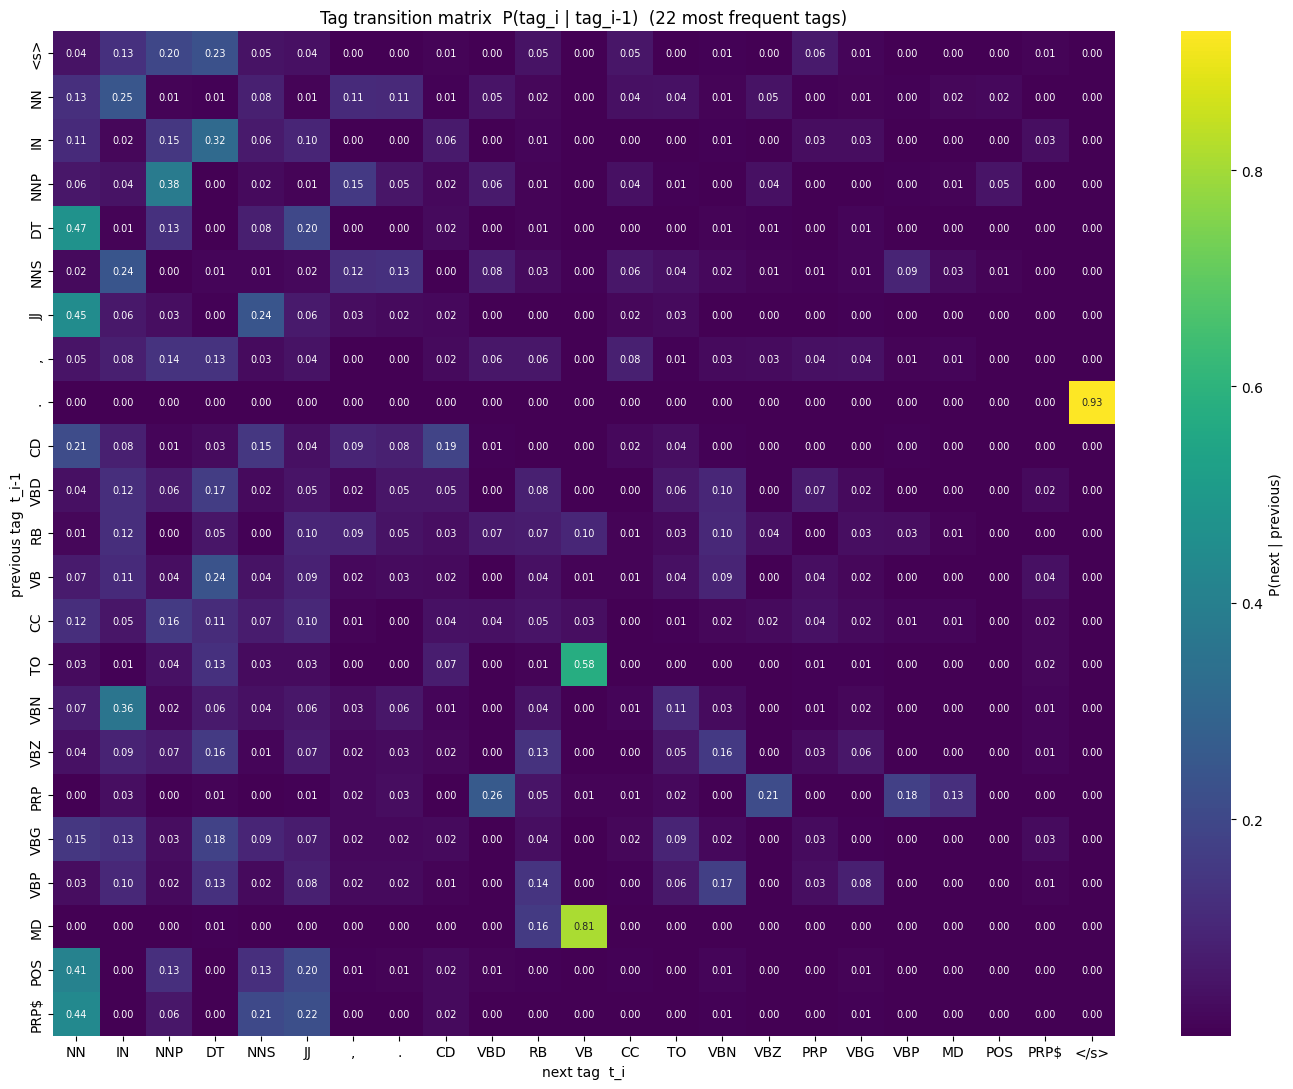

In [9]:
main = tag_df.tag[:22].tolist()   # 22 most frequent tags, for readability
sub = trans_df.loc[["<s>"] + main, main + ["</s>"]]
plt.figure(figsize=(14, 11))
sns.heatmap(sub, cmap="viridis", annot=True, fmt=".2f", annot_kws={"size": 7}, cbar_kws={"label": "P(next | previous)"})
plt.title("Tag transition matrix  P(tag_i | tag_i-1)  (22 most frequent tags)")
plt.xlabel("next tag  t_i"); plt.ylabel("previous tag  t_i-1")
plt.tight_layout(); plt.savefig("model/transition_heatmap.png", dpi=120); plt.show()

In [10]:
# Most probable next tags after each frequent tag: a quick read of the grammar the model learnt
rows = []
for p in ["<s>", "DT", "JJ", "NN", "NNP", "IN", "VBD", "MD", "TO", "PRP"]:
    top = sorted(hmm["trans"][p].items(), key=lambda x: -x[1])[:4]
    rows.append({"previous tag": p, **{f"#{i+1}": f"{t} ({v:.2f})" for i, (t, v) in enumerate(top)}})
pd.DataFrame(rows)

,previous tag,#1,#2,#3,#4
0,<s>,DT (0.23),NNP (0.20),IN (0.13),`` (0.08)
1,DT,NN (0.47),JJ (0.20),NNP (0.13),NNS (0.08)
2,JJ,NN (0.45),NNS (0.24),JJ (0.06),IN (0.06)
3,NN,IN (0.25),NN (0.13),", (0.11)",. (0.11)
4,NNP,NNP (0.38),", (0.15)",VBD (0.06),NN (0.06)
5,IN,DT (0.32),NNP (0.15),NN (0.11),JJ (0.10)
6,VBD,DT (0.17),IN (0.12),VBN (0.10),RB (0.08)
7,MD,VB (0.81),RB (0.16),DT (0.01),`` (0.00)
8,TO,VB (0.58),DT (0.13),CD (0.07),NNP (0.04)
9,PRP,VBD (0.26),VBZ (0.21),VBP (0.18),MD (0.13)


In [11]:
# --- Emission probabilities P(word | tag) for all observed pairs
em_rows = [(w, t, c, emit_prob(hmm, w, t)) for w, d in hmm["wt_counts"].items() for t, c in d.items()]
em_df = pd.DataFrame(em_rows, columns=["word", "tag", "count", "P(word|tag)"]).sort_values(["tag", "P(word|tag)"], ascending=[True, False])
em_df.to_csv("model/emission_probs.csv", index=False)
print("Emission table rows:", len(em_df))
# Top 5 words per major tag
em_df.groupby("tag").head(5).query("tag in ['NN','NNS','NNP','VB','VBD','VBZ','JJ','RB','IN','DT']").reset_index(drop=True)

Emission table rows: 13341


,word,tag,count,P(word|tag)
0,the,DT,4038,0.493826
1,a,DT,1874,0.229180
2,The,DT,713,0.087196
3,an,DT,316,0.038645
4,this,DT,184,0.022502
5,of,IN,2319,0.234979
6,in,IN,1554,0.157463
7,for,IN,815,0.082582
8,that,IN,513,0.051981
9,on,IN,483,0.048941


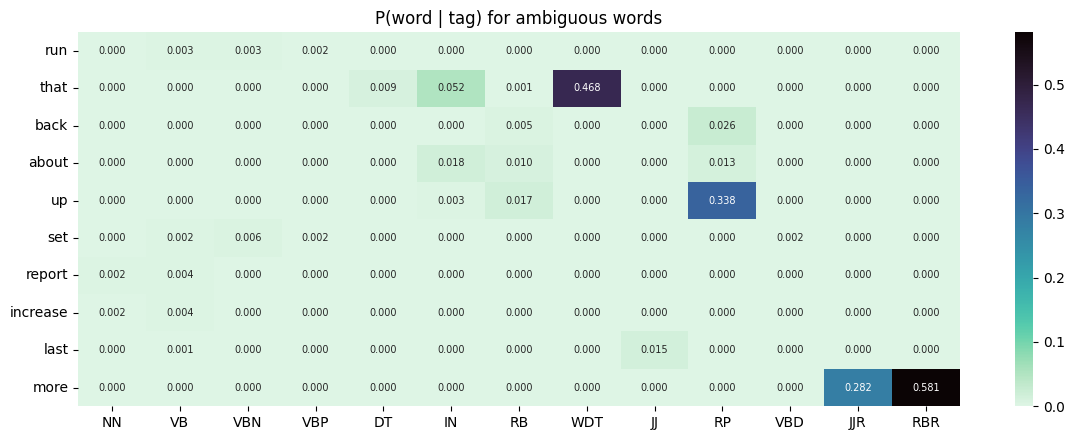

,UNK,UNK-CAP,UNK-CAP-HYPH,UNK-CAP-HYPH-ed,UNK-CAP-HYPH-er,UNK-CAP-HYPH-ic,UNK-CAP-HYPH-ies,UNK-CAP-HYPH-ing,UNK-CAP-HYPH-ive,UNK-CAP-HYPH-s,UNK-CAP-HYPH-tion,UNK-CAP-able,UNK-CAP-al,UNK-CAP-ed,UNK-CAP-er,UNK-CAP-ers,UNK-CAP-est,UNK-CAP-ible,UNK-CAP-ic,UNK-CAP-ies,UNK-CAP-ing,UNK-CAP-ity,UNK-CAP-ive,UNK-CAP-ly,UNK-CAP-ment,UNK-CAP-ous,UNK-CAP-s,UNK-CAP-sion,UNK-CAP-tion,UNK-HYPH,...,UNK-HYPH-s,UNK-HYPH-tion,UNK-NUM,UNK-NUM-CAP,UNK-NUM-CAP-HYPH,UNK-NUM-HYPH,UNK-NUM-HYPH-er,UNK-NUM-HYPH-s,UNK-NUM-HYPH-tion,UNK-NUM-s,UNK-able,UNK-al,UNK-ed,UNK-er,UNK-ers,UNK-est,UNK-ful,UNK-ible,UNK-ic,UNK-ies,UNK-ing,UNK-ity,UNK-ive,UNK-ly,UNK-ment,UNK-ness,UNK-ous,UNK-s,UNK-sion,UNK-tion
most likely tag for an unseen word,NN,NNP,NNP,JJ,NNP,NNP,NNPS,NNP,JJ,NNS,JJ,JJ,NNP,VBN,NNP,NNS,NNP,JJ,NNP,NNS,VBG,NNP,NNP,RB,NNP,JJ,NNP,NNP,NNP,JJ,...,NNS,JJ,CD,CD,NN,JJ,JJ,NNS,JJ,CD,JJ,JJ,VBN,NN,NNS,JJS,JJ,JJ,JJ,NNS,VBG,NN,JJ,RB,NN,NN,JJ,NNS,NN,NN


In [12]:
# Emission matrix for a few ambiguous words (rows: words, columns: tags)
amb = ["run", "that", "back", "about", "up", "set", "report", "increase", "last", "more"]
amb_mat = pd.DataFrame({w: {t: emit_prob(hmm, w, t) for t in TAGS if hmm["wt_counts"].get(w, {}).get(t)} for w in amb}).T.fillna(0)
plt.figure(figsize=(12, 4.5))
sns.heatmap(amb_mat, cmap="mako_r", annot=True, fmt=".3f", annot_kws={"size": 7})
plt.title("P(word | tag) for ambiguous words"); plt.tight_layout(); plt.savefig("model/emission_ambiguous.png", dpi=120); plt.show()

unk_df = pd.DataFrame(hmm["unk"]).T
unk_df.to_csv("model/unknown_word_model.csv")
# Which tag an unseen word of each shape is most likely to get, P(tag | sig) ∝ P(sig | tag) P(tag)
prior = {t: hmm["tag_counts"][t] for t in TAGS}
best_for_sig = {s: max(TAGS, key=lambda t: hmm["unk"][t][s] * prior[t]) for s in hmm["signatures"]}
pd.Series(best_for_sig, name="most likely tag for an unseen word").to_frame().T

## 3. PCFG induction from the treebank parse trees

Tree preparation:
1. remove empty elements (`-NONE-`) and any constituent left empty by that;
2. strip function tags and co-indices (`NP-SBJ-1` → `NP`, `PP-LOC` → `PP`);
3. add a `TOP` root symbol.

**Two grammars are produced:**

* **Lexicalised PCFG** (`pcfg_grammar_lexicalised.txt`): `nltk.induce_pcfg` over the original n-ary trees, including word rules such as `NN → 'market'`. This is the full "PCFG parser data": the probability of each rule, estimated by maximum likelihood, P(A → β) = C(A → β) / C(A).
* **Parser grammar (CNF, tag level)**: the terminals are POS tags. Unary chains are collapsed (`S+VP`) and rules are binarised with horizontal Markovisation of order 1 (`NP|<NN>`), which gives Chomsky Normal Form for the CKY parser. Parsing tag sequences lets the parser score the *grammatical structure* of any sentence, including one full of unseen Sri Lankan names; word-level evidence is already covered by the HMM.

In [13]:
def clean_tree(t):
    if isinstance(t, str):
        return t
    lab = t.label()
    if lab == "-NONE-":
        return None
    if lab not in ("-LRB-", "-RRB-"):
        lab = re.split(r"[-=]", lab)[0] or lab
    kids = [c for c in (clean_tree(k) for k in t) if c is not None]
    return Tree(lab, kids) if kids else None

clean_trees = [c for c in (clean_tree(t) for t in parsed_raw) if c is not None]
clean_trees = [Tree("TOP", [t]) for t in clean_trees]
print(len(clean_trees), "trees")
clean_trees[1].pretty_print()

3914 trees
                                             TOP                                    
                                              |                                      
                                              S                                     
      ________________________________________|___________________________________   
     |                VP                                                          | 
     |           _____|____________                                               |  
     |          |                  NP                                             | 
     |          |      ____________|_______________                               |  
     |          |     |                            PP                             | 
     |          |     |       _____________________|___                           |  
     |          |     |      |                         NP                         | 
     |          |     |      |             ______

In [14]:
# ---- Lexicalised PCFG (n-ary rules + word rules)
lex_prods = [p for t in clean_trees for p in t.productions()]
lex_pcfg = induce_pcfg(Nonterminal("TOP"), lex_prods)
rule_counts = collections.Counter(lex_prods)
lhs_counts = collections.Counter(p.lhs() for p in lex_prods)

pcfg_rows = [{"lhs": str(p.lhs()), "rhs": " ".join(str(x) if not isinstance(x, str) else repr(x) for x in p.rhs()),
              "lexical": p.is_lexical(), "count": rule_counts[p], "prob": rule_counts[p] / lhs_counts[p.lhs()]}
             for p in rule_counts]
pcfg_df = pd.DataFrame(pcfg_rows).sort_values(["lhs", "prob"], ascending=[True, False]).reset_index(drop=True)
pcfg_df.to_csv("model/pcfg_rules.csv", index=False)
with open("model/pcfg_grammar_lexicalised.txt", "w", encoding="utf-8") as f:
    f.write(str(lex_pcfg))
print(f"Lexicalised PCFG: {len(lex_pcfg.productions())} rules "
      f"({(~pcfg_df.lexical).sum()} phrasal, {pcfg_df.lexical.sum()} lexical), "
      f"{pcfg_df.lhs.nunique()} left-hand sides")

Lexicalised PCFG: 17105 rules (3764 phrasal, 13341 lexical), 73 left-hand sides


In [15]:
# The most probable expansions of the main phrase categories
top_rules = (pcfg_df[~pcfg_df.lexical & pcfg_df.lhs.isin(["S", "NP", "VP", "PP", "SBAR", "ADJP"])]
             .groupby("lhs").head(6).reset_index(drop=True))
top_rules.assign(prob=top_rules.prob.round(4))

,lhs,rhs,lexical,count,prob
0,ADJP,JJ,False,265,0.2048
1,ADJP,JJ PP,False,125,0.0966
2,ADJP,RB JJ,False,122,0.0943
3,ADJP,JJ S,False,58,0.0448
4,ADJP,QP,False,58,0.0448
5,ADJP,CD NN,False,57,0.0440
6,NP,NP PP,False,3507,0.1124
7,NP,DT NN,False,2877,0.0922
8,NP,PRP,False,1705,0.0546
9,NP,NNS,False,1324,0.0424


In [16]:
# ---- Tag-level CNF grammar for the CKY parser
def to_tag_tree(t):
    # replace words by their POS tags:  (NN market) -> (NN NN)
    t = t.copy(deep=True)
    for pos in t.treepositions("leaves"):
        t[pos] = t[pos[:-1]].label()
    return t

def binarise(t, horz=1):
    t = to_tag_tree(t)
    t.collapse_unary(collapsePOS=True, collapseRoot=False)
    t.chomsky_normal_form(horzMarkov=horz)
    return t

def build_parser_grammar(trees, horz=1):
    prods = [p for t in trees for p in binarise(t, horz).productions()]
    g = induce_pcfg(Nonterminal("TOP"), prods)
    binary = collections.defaultdict(list)   # (B, C) -> [(A, logp)]
    lexical = collections.defaultdict(list)  # tag  -> [(A, logp)]
    root = {}                                # X -> log P(TOP -> X)
    for p in g.productions():
        A, rhs, lp = str(p.lhs()), p.rhs(), math.log(p.prob())
        if A == "TOP" and len(rhs) == 1 and not isinstance(rhs[0], str):
            root[str(rhs[0])] = lp
        elif len(rhs) == 1 and isinstance(rhs[0], str):
            lexical[rhs[0]].append((A, lp))
        elif len(rhs) == 2:
            binary[(str(rhs[0]), str(rhs[1]))].append((A, lp))
        else:
            raise ValueError(f"not CNF: {p}")
    return g, dict(binary), dict(lexical), root

cnf_pcfg, BIN, LEX, ROOT = build_parser_grammar(clean_trees)
with open("model/pcfg_parser_grammar_cnf.txt", "w", encoding="utf-8") as f:
    f.write(str(cnf_pcfg))
print(f"CNF parser grammar: {len(cnf_pcfg.productions())} rules, {len({str(p.lhs()) for p in cnf_pcfg.productions()})} non-terminals, "
      f"{sum(map(len, BIN.values()))} binary, {sum(map(len, LEX.values()))} preterminal, {len(ROOT)} root rules")
binarise(clean_trees[1]).pretty_print()

CNF parser grammar: 4783 rules, 761 non-terminals, 4621 binary, 151 preterminal, 11 root rules
                                  TOP                                                
                                   |                                                  
                                   S                                                 
      _____________________________|____                                              
     |                                S|<VP>                                         
     |             _____________________|__________________________________________   
     |            VP                                                               | 
     |        ____|________                                                        |  
     |       |             NP                                                      | 
     |       |     ________|____________                                           |  
     |       |    |                     

## 4. Probabilistic CKY parser

Viterbi CKY over the tag sequence returns the most probable parse tree and its log-probability, log P(T*, t₁…tₙ). Each chart cell keeps its 40 best constituents (beam pruning) so that long news sentences parse in well under a second. If the grammar cannot build one tree over the whole sentence, `cky_parse_robust` falls back to a **fragment parse**: the smallest number of constituents that together cover the sentence (then the most probable such set). Every join the grammar could not make is charged the log-probability of the grammar's rarest binary rule, which keeps fragment scores comparable with full parses. The number of fragments is itself a useful measure of how far a sentence departs from treebank structure. The binarised tree is then converted back to ordinary n-ary form for display and evaluation.

In [17]:
def cky_chart(tags, BIN, LEX, beam=40):
    n = len(tags)
    chart = [[None] * (n + 1) for _ in range(n + 1)]
    for i, t in enumerate(tags):
        chart[i][i + 1] = {A: (lp, t) for A, lp in LEX.get(t, [])}
    for span in range(2, n + 1):
        for i in range(0, n - span + 1):
            j = i + span; cell = {}
            for k in range(i + 1, j):
                L, R = chart[i][k], chart[k][j]
                if not L or not R: continue
                for B, (lb, _) in L.items():
                    for C, (lc, _) in R.items():
                        rules = BIN.get((B, C))
                        if not rules: continue
                        base = lb + lc
                        for A, lp in rules:
                            s = base + lp
                            if A not in cell or s > cell[A][0]:
                                cell[A] = (s, (k, B, C))
            if len(cell) > beam:
                cell = dict(sorted(cell.items(), key=lambda x: -x[1][0])[:beam])
            chart[i][j] = cell
    return chart

def build_tree(chart, i, j, A):
    bp = chart[i][j][A][1]
    if isinstance(bp, str):
        return Tree(A, [bp])
    k, B, C = bp
    return Tree(A, [build_tree(chart, i, k, B), build_tree(chart, k, j, C)])

def cky_parse(tags, BIN, LEX, ROOT, beam=40):
    # most probable full parse: returns (tree, log P) or (None, -inf) if the grammar cannot span the sentence
    n = len(tags); chart = cky_chart(tags, BIN, LEX, beam)
    top = chart[0][n] or {}
    cands = [(top[X][0] + lp, X) for X, lp in ROOT.items() if X in top]
    if not cands:
        return None, float("-inf")
    best, X = max(cands)
    return Tree("TOP", [build_tree(chart, 0, n, X)]), best

def cky_parse_robust(tags, BIN, LEX, ROOT, beam=40):
    # Full parse if possible; otherwise the fewest, most probable constituents that cover the sentence
    # (a fragment parse). Returns (tree, log P, number_of_fragments); 1 fragment = full parse.
    n = len(tags); chart = cky_chart(tags, BIN, LEX, beam)
    top = chart[0][n] or {}
    cands = [(top[X][0] + lp, X) for X, lp in ROOT.items() if X in top]
    if cands:
        best, X = max(cands)
        return Tree("TOP", [build_tree(chart, 0, n, X)]), best, 1
    # DP over split points: minimise #fragments, then maximise log-probability
    best = [(0, 0.0, None)] + [(10**9, float("-inf"), None)] * n
    for j in range(1, n + 1):
        for i in range(j):
            if best[i][0] >= 10**9 or not chart[i][j]: continue
            A, (lp, _) = max(chart[i][j].items(), key=lambda x: x[1][0])
            cand = (best[i][0] + 1, best[i][1] + lp, (i, A))
            if (cand[0], -cand[1]) < (best[j][0], -best[j][1]):
                best[j] = cand
    frags, j = [], n
    while j > 0:
        i, A = best[j][2]; frags.append(build_tree(chart, i, j, A)); j = i
    # each extra fragment is charged the log-probability of the rarest binary rule in the grammar,
    # so a fragment parse can never look more probable than a full parse of the same length
    penalty = min(lp for rules in BIN.values() for _, lp in rules)
    return Tree("TOP", [Tree("FRAG", frags[::-1])]), best[n][1] + (best[n][0] - 1) * penalty, best[n][0]

def debinarise(t):
    # Undo the CNF transform: splice out artificial "X|<...>" nodes and expand collapsed unary chains "A+B".
    # (Written by hand instead of nltk's un_chomsky_normal_form, whose behaviour differs between NLTK versions.)
    def rec(node):
        if isinstance(node, str):
            return [node]
        kids = [k for c in node for k in rec(c)]
        lab = node.label()
        if "|<" in lab:
            return kids
        parts = lab.split("+")
        tree = Tree(parts[-1], kids)
        for p in reversed(parts[:-1]):
            tree = Tree(p, [tree])
        return [tree]
    out = rec(t)
    return out[0] if len(out) == 1 else Tree("TOP", out)

demo = [t for _, t in tagged_sents[1]]
t0 = time.time(); tr, lp = cky_parse(demo, BIN, LEX, ROOT)
print(f"{len(demo)} tags, logP = {lp:.2f}, {time.time()-t0:.2f}s"); debinarise(tr).pretty_print()

13 tags, logP = -31.86, 0.01s
                                    TOP                                
                                     |                                  
                                     S                                 
                  ___________________|_______________________________   
                 S                       |       |           |       | 
      ___________|___                    |       |           |       |  
     |               VP                  |       |           |       | 
     |        _______|___                |       |           |       |  
     |       |           NP              |       |           |       | 
     |       |    _______|___            |       |           |       |  
     |       |   |           PP          |       |           VP      | 
     |       |   |    _______|___        |       |        ___|___    |  
     NP      |   NP  |           NP      |       NP      |       NP  | 
  ___|___    |   |   |      

### 4.1 Validate the parser (PARSEVAL on held-out training files)

The grammar is re-induced from the 90 % split and used to parse the held-out 10 % sentences (up to 40 tokens), with their gold POS tags as input. Labelled bracket precision, recall and F1 follow the standard PARSEVAL definition, ignoring the TOP node and preterminals.

In [18]:
def brackets(t):
    out = collections.Counter()
    def walk(node, start):
        if isinstance(node, str): return start + 1
        if node.height() == 2: return start + 1   # preterminal
        end = start
        for c in node: end = walk(c, end)
        if node.label() != "TOP": out[(node.label(), start, end)] += 1
        return end
    walk(t, 0); return out

fit_trees = [Tree("TOP", [c]) for f in fileids if f not in dev_files for c in [clean_tree(t) for t in treebank.parsed_sents(f)] if c is not None]
dev_trees = [Tree("TOP", [c]) for f in sorted(dev_files) for c in [clean_tree(t) for t in treebank.parsed_sents(f)] if c is not None]
_, BIN_d, LEX_d, ROOT_d = build_parser_grammar(fit_trees)

match = n_gold = n_pred = 0; parsed = total = 0; t0 = time.time()
for gt in dev_trees:
    tags = [t for _, t in gt.pos()]
    if len(tags) > 40: continue
    total += 1
    pt, lp = cky_parse(tags, BIN_d, LEX_d, ROOT_d)
    g = brackets(gt); n_gold += sum(g.values())
    if pt is None: continue
    parsed += 1
    p = brackets(debinarise(pt)); n_pred += sum(p.values())
    match += sum((g & p).values())
P, R = match / n_pred, match / n_gold
parseval = {"sentences": total, "coverage": parsed / total, "labelled_precision": P, "labelled_recall": R, "labelled_F1": 2*P*R/(P+R)}
print(f"time {time.time()-t0:.0f}s"); pd.Series(parseval).round(4)

time 30s


sentences             305.0000
coverage                0.9836
labelled_precision      0.7712
labelled_recall         0.7340
labelled_F1             0.7522
dtype: float64

## 5. Save the model for Task 3

In [19]:
model = dict(hmm=hmm, BIN=BIN, LEX=LEX, ROOT=ROOT, PTB_TAGS=PTB_TAGS, SUFFIXES=SUFFIXES,
             validation=dict(tagging_accuracy=float(acc), parseval=parseval),
             info="Bigram HMM (add-0.1 transitions, hapax signature unknown-word model) + tag-level PCFG (CNF, h=1) from NLTK PTB WSJ sample")
with open("model/pos_pcfg_model.pkl", "wb") as f:
    pickle.dump(model, f)
for fn in sorted(os.listdir("model")):
    print(f"{fn:36s} {os.path.getsize('model/'+fn)/1024:8.1f} KB")

emission_ambiguous.png                   54.9 KB
emission_probs.csv                      468.7 KB
pcfg_grammar_lexicalised.txt            580.4 KB
pcfg_parser_grammar_cnf.txt             169.7 KB
pcfg_rules.csv                          726.7 KB
pos_pcfg_model.pkl                      564.6 KB
tag_counts.csv                            2.1 KB
tag_frequencies.png                      39.6 KB
transition_counts.csv                     5.2 KB
transition_heatmap.png                  198.3 KB
transition_matrix.csv                    44.8 KB
unknown_word_model.csv                   73.6 KB


## 6. Model summary

| Component | Estimation | Held-out quality |
|---|---|---|
| Tag transitions P(tᵢ\|tᵢ₋₁) | bigram MLE with add-0.1 smoothing | – |
| Emissions P(w\|t) | MLE + signature pseudo-count; hapax-based unknown-word model | – |
| POS tagger (Viterbi) | – | accuracy printed in §2.1 (typically ≈ 0.93–0.95) |
| PCFG (tag level, CNF) | MLE rule probabilities from treebank trees | PARSEVAL labelled F1 printed in §4.1 |

The Task 3 notebook loads `model/pos_pcfg_model.pkl` and uses the HMM and the PCFG together to score each of the 150 Daily Mirror sentences.

## 7. (Optional) The Kaggle `ptb.train.txt` file

If the Kaggle file is placed next to this notebook, the cell below shows why it cannot train a tagger (no tags) and reports how much of its vocabulary the labelled model covers.

In [20]:
if os.path.exists("ptb.train.txt"):
    lines = open("ptb.train.txt", encoding="utf-8").read().splitlines()
    print(len(lines), "lines; first line:", lines[0][:120])
    kv = collections.Counter(w for l in lines for w in l.split())
    cov = sum(c for w, c in kv.items() if lookup(hmm, w)) / sum(kv.values())
    print(f"Kaggle vocabulary size {len(kv)}; token coverage by the labelled-model vocabulary: {cov:.1%}")
else:
    print("ptb.train.txt not present: skipped (it contains no POS tags, so it is not needed for training).")

ptb.train.txt not present: skipped (it contains no POS tags, so it is not needed for training).
